In [1]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
categorical_columns

['lead_source', 'industry', 'employment_status', 'location']

In [7]:
numerical_columns = list(df.dtypes[df.dtypes != 'str'].index)
numerical_columns

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [8]:
df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna('0')

df.isnull().sum()


lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
df['industry'].mode()[0]

'technology'

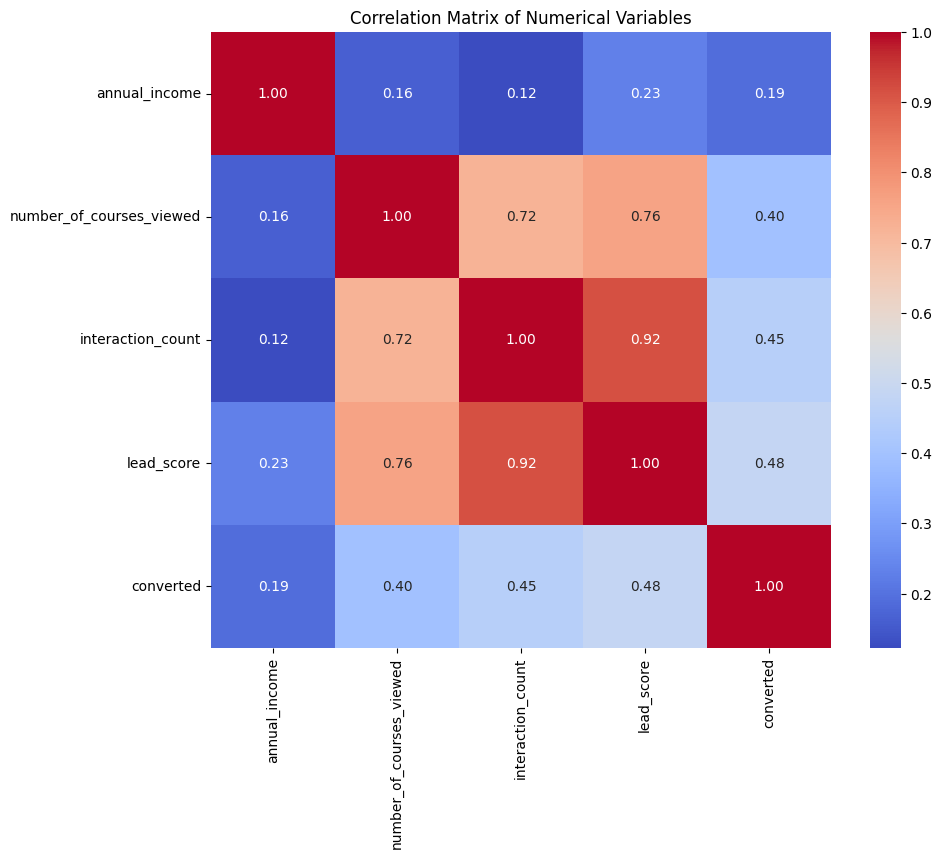

In [10]:
corr_matrix = df[numerical_columns].corr()


plt.figure(figsize = (10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Variables')
plt.show()


In [11]:
from sklearn.model_selection import train_test_split


df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [12]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

In [13]:
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

del df_train['converted']
del df_val['converted']
del df_test['converted']
del df_full_train['converted']

In [14]:
from sklearn.metrics import mutual_info_score

def calculate_mi(series):
    return mutual_info_score(series, y_train)

In [15]:
mi = df_train[categorical_columns].apply(calculate_mi)
round(mi.sort_values(ascending=False), 2)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [16]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [17]:
numerical_columns.remove('converted')
train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')


dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dict)

In [18]:
X_train.shape

(3000, 30)

In [19]:
val_dict = df_val[categorical_columns + numerical_columns].to_dict(orient='records')
X_val = dv.transform(val_dict)
X_val.shape

(1000, 30)

In [20]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [23]:
y_pred = model.predict(X_val)
orig_accuracy = accuracy_score(y_val, y_pred)
orig_accuracy

0.645

In [24]:
differences = {}


for feature in categorical_columns + numerical_columns:

    subset = [f for f in categorical_columns + numerical_columns if f != feature]

    train_dict = df_train[subset].to_dict(orient='records')
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(train_dict)

    val_dict = df_val[subset].to_dict(orient='records')
    X_val_sub = dv_sub.transform(val_dict)

    model_sub = LogisticRegression(solver='liblinear', C=10, max_iter=1000, random_state=42)
    model_sub.fit(X_train_sub, y_train)


    y_pred_sub = model_sub.predict(X_val_sub)
    acc_sub = accuracy_score(y_val, y_pred_sub)

    diff = orig_accuracy - acc_sub
    differences[feature] = diff
    
    print(f"Без '{feature:20s}': точність = {acc_sub:.6f} | різниця = {diff:.6f}")
    

Без 'lead_source         ': точність = 0.642000 | різниця = 0.003000
Без 'industry            ': точність = 0.645000 | різниця = 0.000000
Без 'employment_status   ': точність = 0.645000 | різниця = 0.000000
Без 'location            ': точність = 0.645000 | різниця = 0.000000
Без 'annual_income       ': точність = 0.727000 | різниця = -0.082000
Без 'number_of_courses_viewed': точність = 0.643000 | різниця = 0.002000
Без 'interaction_count   ': точність = 0.600000 | різниця = 0.045000
Без 'lead_score          ': точність = 0.644000 | різниця = 0.001000


In [29]:
features = categorical_columns + numerical_columns

train_dict = df_train[features].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

val_dict = df_val[features].to_dict(orient='records')
X_val = dv.transform(val_dict)

c = [0.000001, 0.00001, 0.0001, 0.001]


scores = {}

for i in c :
    model = LogisticRegression(solver='liblinear', C=i, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    score = accuracy_score(y_val, y_pred)

    scores[i] = score
    print(f"C = {i:<6} | Accuracy = {score:.5f} | {round(score, 3)}")


best_c = max(scores, key=scores.get)
print(f"\nНайкраще C: {best_c} з точністю {scores[best_c]:.5f}")    



C = 1e-06  | Accuracy = 0.59800 | 0.598
C = 1e-05  | Accuracy = 0.59800 | 0.598
C = 0.0001 | Accuracy = 0.61300 | 0.613
C = 0.001  | Accuracy = 0.64500 | 0.645

Найкраще C: 0.001 з точністю 0.64500
